# 01 图像与像素：一切都是矩阵

**学习目标**
- 理解图像在计算机里就是一个 NumPy 数组（像素矩阵）
- 会用 OpenCV 读取/保存/显示图片，搞懂 BGR 与 RGB 的区别
- 会做像素级操作：访问像素、切片取 ROI、拆分通道
- 手写一个 3x3 均值滤波器，并与 cv2.blur 对比

> 对应冈萨雷斯《数字图像处理》第 1~2 章：图像数字化、像素间关系。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

print('numpy:', np.__version__)
print('opencv:', cv2.__version__)

numpy: 2.2.6
opencv: 5.0.0


## 1. 图像就是 NumPy 数组

先不读真实图片，直接用代码**造**一张灰度图：水平渐变 + 一个亮方块 + 一个圆。
观察它的 shape、dtype、像素值范围——这就是‘图像=矩阵’的含义。

shape: (200, 300)  dtype: uint8
像素值范围: 0 ~ 255
(0,0) 处像素值: 0


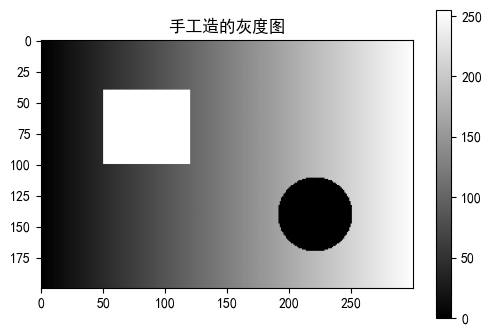

In [2]:
h, w = 200, 300
img = np.tile(np.linspace(0, 255, w, dtype=np.uint8), (h, 1))  # 水平渐变
img[40:100, 50:120] = 255                                       # 亮方块
yy, xx = np.ogrid[:h, :w]
img[(yy - 140) ** 2 + (xx - 220) ** 2 < 30 ** 2] = 0            # 黑圆

print('shape:', img.shape, ' dtype:', img.dtype)
print('像素值范围:', img.min(), '~', img.max())
print('(0,0) 处像素值:', img[0, 0])

plt.figure(figsize=(6, 4))
plt.imshow(img, cmap='gray', vmin=0, vmax=255)
plt.title('手工造的灰度图')
plt.colorbar()
plt.show()

## 2. OpenCV 读写与 BGR 大坑

cv2.imread 读进来的彩色图通道顺序是 **BGR**，而 matplotlib 按 **RGB** 显示，
直接显示会偏色——这是新手必踩的坑。先保存一张彩色图再读回来验证。

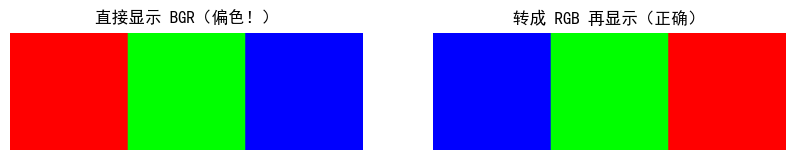

In [3]:
color = np.zeros((120, 360, 3), dtype=np.uint8)
color[:, :120] = (0, 0, 255)      # 红色（RGB 思维写）
color[:, 120:240] = (0, 255, 0)   # 绿色
color[:, 240:] = (255, 0, 0)      # 蓝色
cv2.imwrite('test_rgb.png', cv2.cvtColor(color, cv2.COLOR_RGB2BGR))

bgr = cv2.imread('test_rgb.png')            # OpenCV 读出：BGR
rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)  # 转回 RGB

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].imshow(bgr); ax[0].set_title('直接显示 BGR（偏色！）'); ax[0].axis('off')
ax[1].imshow(rgb); ax[1].set_title('转成 RGB 再显示（正确）'); ax[1].axis('off')
plt.show()

## 3. 像素操作：切片取 ROI、通道拆分

图像数组的切片就是‘裁剪区域’（ROI，Region of Interest），
cv2.split 可以把三个通道拆开单独看。

ROI shape: (80, 90)


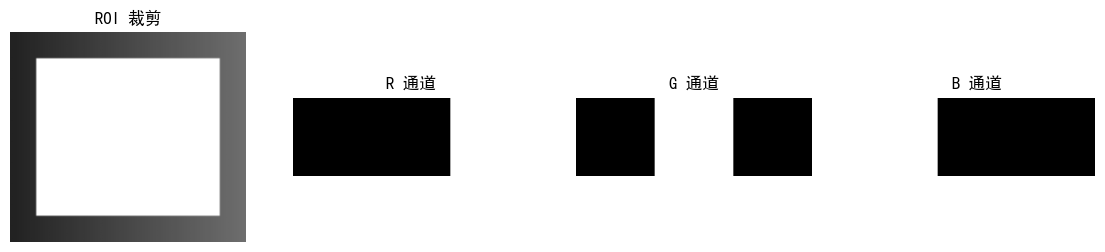

In [4]:
roi = img[30:110, 40:130]   # 取出亮方块所在的区域
print('ROI shape:', roi.shape)

b, g, r = cv2.split(bgr)

fig, ax = plt.subplots(1, 4, figsize=(14, 3))
ax[0].imshow(roi, cmap='gray', vmin=0, vmax=255); ax[0].set_title('ROI 裁剪')
for a, ch, name in zip(ax[1:], (r, g, b), 'RGB'):
    a.imshow(ch, cmap='gray', vmin=0, vmax=255)
    a.set_title(f'{name} 通道')
for a in ax: a.axis('off')
plt.show()

## 4. 手写 3x3 均值滤波 vs cv2.blur

均值滤波：每个像素用它周围 3x3 邻域的平均值代替，能平滑噪声。
先给图加椒盐噪声，再手写滤波（双重循环，最朴素的实现），最后和 OpenCV 的结果对比。

> 用你信号处理的视角看：均值滤波就是一个 3x3 的二维低通 FIR 滤波器。

两种实现的最大差异: 227 （边界处理不同，内部应接近 0）


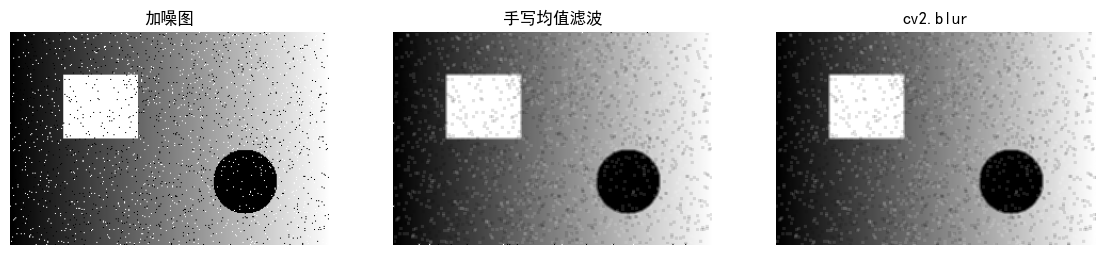

In [5]:
rng = np.random.default_rng(42)
noisy = img.copy()
mask = rng.random(img.shape)
noisy[mask < 0.02] = 0      # 2% 黑点
noisy[mask > 0.98] = 255    # 2% 白点

def mean_filter_3x3(src):
    dst = src.copy()
    for i in range(1, src.shape[0] - 1):
        for j in range(1, src.shape[1] - 1):
            dst[i, j] = src[i-1:i+2, j-1:j+2].mean()
    return dst

mine = mean_filter_3x3(noisy)
theirs = cv2.blur(noisy, (3, 3))

diff = np.abs(mine.astype(int) - theirs.astype(int))
print('两种实现的最大差异:', diff.max(), '（边界处理不同，内部应接近 0）')

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].imshow(noisy, cmap='gray', vmin=0, vmax=255); ax[0].set_title('加噪图')
ax[1].imshow(mine, cmap='gray', vmin=0, vmax=255); ax[1].set_title('手写均值滤波')
ax[2].imshow(theirs, cmap='gray', vmin=0, vmax=255); ax[2].set_title('cv2.blur')
for a in ax: a.axis('off')
plt.show()

## 练习（自己完成，下节课对答案）

1. 把测试图**上下翻转**再**左右翻转**，各用一行 NumPy 切片实现
2. 统计灰度图 img 的直方图，用 plt.hist 画出来（提示：img.ravel()）
3. 把 3x3 均值滤波改成 **5x5**，对比平滑效果的差异

---
下一课预告：02 灰度变换与直方图（点运算、伽马校正、直方图均衡化）